# Modellierung – Bekannter Test und Fehleranalyse

Wir bewerten den bereits bekannten Testzeitraum September 2025 bis August 2026. Der in der jährlichen Validierung ausgewählte Kandidat bleibt unverändert.

Wir vergleichen Vorhersagen mit tatsächlichen Werten und untersuchen Fehler sowie ein exploratives Fehlerband. Der bekannte Test ist kein unabhängiger Erfolgsnachweis.

## 1. Vorhersagen und Modellauswahl laden

Wir übernehmen die gespeicherten Vorhersagen, den Prüfplan und die Modellauswahl. Für das Fehlerband laden wir zusätzlich die monatlichen Validierungsprognosen.

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


project_dir = Path(
    r"C:\Users\mmatavela\Desktop\House_Demand_Forecasting"
)
results_dir = project_dir / "ergebnisse" / "modellierung"
figures_dir = results_dir / "grafiken"
figures_dir.mkdir(parents=True, exist_ok=True)

predictions_data = pd.read_csv(results_dir / "all_predictions.csv")
run_protocol = json.loads(
    (results_dir / "run_protocol.json").read_text(encoding="utf-8")
)
selection = json.loads(
    (results_dir / "selection.json").read_text(encoding="utf-8")
)
selected_model = selection["selected_model"]
test_origin = pd.Period(run_protocol["test_origin"], freq="M")
target_delay = run_protocol["target_delay_months"]

test_predictions = predictions_data.loc[
    predictions_data["origin"] == str(test_origin)
].copy()
monthly_predictions = predictions_data.loc[
    predictions_data["origin"].isin(run_protocol["monthly_origins"])
].copy()
assert test_predictions.groupby("model").size().eq(12).all()

dark_blue = "#173F63"
blue = "#4B91BF"
red = "#B52835"
plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.labelsize": 10
})
print("Ausgewählter Kandidat:", selected_model)
print("Bekannter Test:", test_origin + 1, "bis", test_origin + 12)

Ausgewählter Kandidat: GB Basis
Bekannter Test: 2025-09 bis 2026-08


## 2. Vorhersagen im bekannten Test bewerten

Wir berechnen MAE, MASE, WAPE und Bias für den ausgewählten Kandidaten und drei Vergleichsmodelle. Die Grafik zeigt die tatsächlichen Werte, die ausgewählte Prognose und Seasonal Naive.

Die Testwerte führen nicht zu einer nachträglichen Modellauswahl.

,MAE,MASE,WAPE (%),Bias (Listings)
model,,,,
GB Basis,303.1,0.506,14.8,+235.2
Seasonal Naive,329.5,0.550,16.1,+329.5
ETS ohne Trend,207.2,0.346,10.1,+106.6
Seasonal Mean 3Y,182.8,0.305,8.9,+104.7


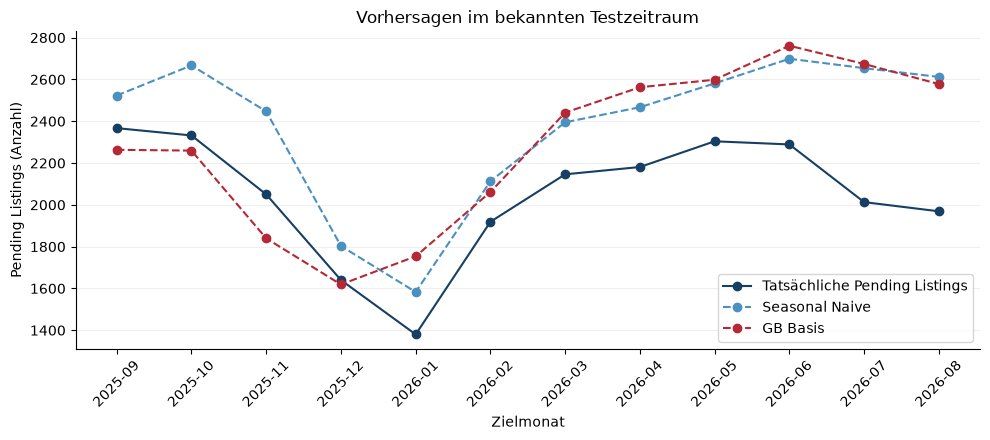

In [2]:
test_models = list(dict.fromkeys([
    selected_model, "Seasonal Naive", "ETS ohne Trend", "Seasonal Mean 3Y"
]))
test_rows = []

for model_name in test_models:
    model_data = (
        test_predictions.loc[test_predictions["model"] == model_name]
        .sort_values("horizon")
    )
    assert len(model_data) == 12
    errors = model_data["prediction"] - model_data["actual"]
    test_rows.append({
        "model": model_name,
        "mae": errors.abs().mean(),
        "mase": model_data["scaled_error"].mean(),
        "wape": 100 * errors.abs().sum() / model_data["actual"].sum(),
        "bias": errors.mean()
    })

test_summary = pd.DataFrame(test_rows).set_index("model")
display(test_summary.rename(columns={
    "mae": "MAE", "mase": "MASE",
    "wape": "WAPE (%)", "bias": "Bias (Listings)"
}).style.format({
    "MAE": "{:.1f}", "MASE": "{:.3f}",
    "WAPE (%)": "{:.1f}", "Bias (Listings)": "{:+.1f}"
}))

selected_predictions = (
    test_predictions.loc[test_predictions["model"] == selected_model]
    .sort_values("horizon")
    .copy()
)
month_positions = np.arange(len(selected_predictions))
month_labels = selected_predictions["target"].tolist()
fig, ax = plt.subplots()
ax.plot(
    month_positions, selected_predictions["actual"],
    color=dark_blue, marker="o", label="Tatsächliche Pending Listings"
)
for model_name, color in [("Seasonal Naive", blue), (selected_model, red)]:
    model_data = (
        test_predictions.loc[test_predictions["model"] == model_name]
        .sort_values("horizon")
    )
    assert model_data["target"].tolist() == month_labels
    ax.plot(
        month_positions, model_data["prediction"],
        color=color, marker="o", linestyle="--", label=model_name
    )
ax.set_xticks(month_positions, month_labels, rotation=45)
ax.set(
    title="Vorhersagen im bekannten Testzeitraum",
    xlabel="Zielmonat", ylabel="Pending Listings (Anzahl)"
)
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(figures_dir / "04_known_test.png", dpi=200)
plt.show()

test_summary.to_csv(results_dir / "known_test_summary.csv")

## 3. Über- und Unterschätzungen untersuchen

Wir betrachten die Fehler je Zielmonat. Positive Fehler bedeuten Überschätzung, negative Fehler Unterschätzung.

Zusätzlich bestimmen wir die Anzahl überschätzter Monate und den Monat mit der größten absoluten Abweichung.

In [3]:
error_details = selected_predictions[
    ["target", "actual", "prediction"]
].copy()
error_details["error"] = error_details["prediction"] - error_details["actual"]
error_details["absolute_error"] = error_details["error"].abs()

overestimated_months = int((error_details["error"] > 0).sum())
underestimated_months = int((error_details["error"] < 0).sum())
largest_error = error_details.loc[error_details["absolute_error"].idxmax()]

display(error_details.rename(columns={
    "target": "Zielmonat",
    "actual": "Tatsächliche Listings",
    "prediction": "Prognose",
    "error": "Fehler",
    "absolute_error": "Absoluter Fehler"
}).round(1))
print(f"Überschätzte Monate: {overestimated_months}")
print(f"Unterschätzte Monate: {underestimated_months}")
print(
    f"Größte absolute Abweichung: {largest_error['target']} "
    f"mit {largest_error['absolute_error']:.1f} Listings."
)
error_details.to_csv(results_dir / "known_test_monthly_errors.csv", index=False)

,Zielmonat,Tatsächliche Listings,Prognose,Fehler,Absoluter Fehler
6353,2025-09,2367.0,2263.2,-103.8,103.8
6377,2025-10,2332.0,2259.5,-72.5,72.5
6401,2025-11,2050.0,1839.6,-210.4,210.4
6425,2025-12,1640.0,1618.9,-21.1,21.1
6449,2026-01,1380.0,1753.6,373.6,373.6
6473,2026-02,1919.0,2061.6,142.6,142.6
6497,2026-03,2146.0,2441.3,295.3,295.3
6521,2026-04,2181.0,2562.7,381.7,381.7
6545,2026-05,2304.0,2598.6,294.6,294.6
6569,2026-06,2289.0,2761.1,472.1,472.1


Überschätzte Monate: 8
Unterschätzte Monate: 4
Größte absolute Abweichung: 2026-07 mit 661.1 Listings.


## 4. Exploratives Fehlerband

Je Horizont verwenden wir das 80-%-Quantil der absoluten monatlichen Validierungsfehler. Berücksichtigt werden nur Zielwerte, die am Teststart unter der angenommenen Datenverzögerung verfügbar waren.

Das Band ergibt sich aus Prognose ± Fehlerquantil. Es ist weder eine garantierte 80-%-Abdeckung noch mit der WAPE-Toleranz gleichzusetzen.

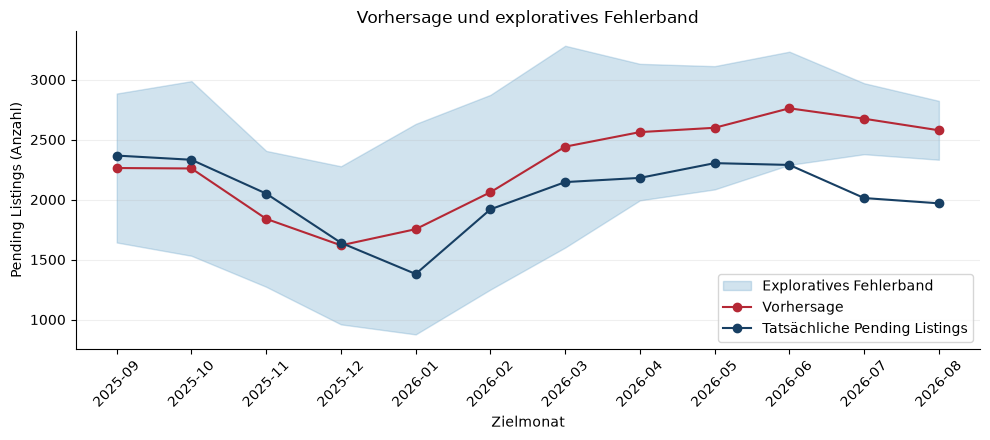

Innerhalb des Fehlerbands: 9 von 12 Monaten (75.0 %).
Mittlere Gesamtbreite des Bands: 1199.8 Listings.


In [4]:
last_available_month = test_origin - target_delay
interval_models = list(dict.fromkeys([
    selected_model, "ETS ohne Trend", "Seasonal Naive"
]))
interval_rows = []

for model_name in interval_models:
    model_test = test_predictions.loc[
        test_predictions["model"] == model_name
    ]
    for row in model_test.itertuples(index=False):
        eligible_predictions = monthly_predictions.loc[
            (monthly_predictions["model"] == model_name)
            & (monthly_predictions["horizon"] == row.horizon)
            & (monthly_predictions["target"] <= str(last_available_month))
        ]
        absolute_errors = eligible_predictions["ae"].to_numpy()
        assert 18 <= len(absolute_errors) <= 20
        error_quantile = float(
            np.quantile(absolute_errors, 0.8, method="higher")
        )
        lower_bound = row.prediction - error_quantile
        upper_bound = row.prediction + error_quantile
        interval_rows.append({
            "model": model_name,
            "horizon": row.horizon,
            "target": row.target,
            "actual": row.actual,
            "prediction": row.prediction,
            "lower": lower_bound,
            "upper": upper_bound,
            "width": upper_bound - lower_bound,
            "calibration_n": len(absolute_errors),
            "covered": lower_bound <= row.actual <= upper_bound
        })

interval_data = pd.DataFrame(interval_rows)
coverage_summary = interval_data.groupby("model").agg(
    covered_months=("covered", "sum"),
    total_months=("covered", "size"),
    coverage=("covered", "mean"),
    mean_width=("width", "mean")
)
selected_intervals = (
    interval_data.loc[interval_data["model"] == selected_model]
    .sort_values("horizon")
)
month_positions = np.arange(len(selected_intervals))
fig, ax = plt.subplots()
ax.fill_between(
    month_positions,
    selected_intervals["lower"].to_numpy(),
    selected_intervals["upper"].to_numpy(),
    color=blue, alpha=0.25, label="Exploratives Fehlerband"
)
ax.plot(
    month_positions, selected_intervals["prediction"],
    color=red, marker="o", label="Vorhersage"
)
ax.plot(
    month_positions, selected_intervals["actual"],
    color=dark_blue, marker="o", label="Tatsächliche Pending Listings"
)
ax.set_xticks(month_positions, selected_intervals["target"], rotation=45)
ax.set(
    title="Vorhersage und exploratives Fehlerband",
    xlabel="Zielmonat", ylabel="Pending Listings (Anzahl)"
)
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(figures_dir / "05_uncertainty.png", dpi=200)
plt.show()

selected_coverage = coverage_summary.loc[selected_model]
print(
    f"Innerhalb des Fehlerbands: "
    f"{int(selected_coverage['covered_months'])} von "
    f"{int(selected_coverage['total_months'])} Monaten "
    f"({100 * selected_coverage['coverage']:.1f} %)."
)
print(
    f"Mittlere Gesamtbreite des Bands: "
    f"{selected_coverage['mean_width']:.1f} Listings."
)
interval_data.to_csv(results_dir / "exploratory_intervals.csv", index=False)
coverage_summary.to_csv(results_dir / "interval_summary.csv")

## 5. Ergebnisse zusammenführen

Wir ergänzen die Zusammenfassung aus Notebook 2 um den bekannten Test. MAE, MASE, WAPE und Bias bleiben nach Prüfbereich getrennt.

Ein gutes Ergebnis im bekannten Test ersetzt keine unabhängige Prüfung. Der anhand der jährlichen Validierung ausgewählte Kandidat bleibt bestehen.

In [6]:
evaluation_summary = pd.read_csv(
    results_dir / "evaluation_summary.csv", index_col=0
)
test_result = test_summary.loc[selected_model]
known_test_row = pd.DataFrame(
    [{
        "model": selected_model,
        "cases": len(selected_predictions),
        "mae": test_result["mae"],
        "mase": test_result["mase"],
        "wape": test_result["wape"],
        "bias": test_result["bias"]
    }],
    index=["Bekannter Test"]
)
final_summary = pd.concat([evaluation_summary, known_test_row])


def classify_wape(wape_value):
    if wape_value <= 12:
        return "Ziel erreicht"
    if wape_value <= 15:
        return "Innerhalb der Toleranz"
    return "Über der Toleranz"


final_summary["assessment"] = final_summary["wape"].apply(classify_wape)
final_summary["cases"] = final_summary["cases"].astype(int)
display(final_summary[
    ["model", "cases", "mae", "mase", "wape", "bias", "assessment"]
].rename(columns={
    "model": "Modell", "cases": "Prognosefälle",
    "mae": "MAE", "mase": "MASE", "wape": "WAPE (%)",
    "bias": "Bias (Listings)", "assessment": "Bewertung"
}).style.format({
    "MAE": "{:.1f}", "MASE": "{:.3f}",
    "WAPE (%)": "{:.1f}", "Bias (Listings)": "{:+.1f}"
}))

reference_mae = test_summary.loc["Seasonal Naive", "mae"]
test_gain = 100 * (1 - test_result["mae"] / reference_mae)
print(
    f"Vorteil gegenüber Seasonal Naive im bekannten Test: {test_gain:.1f} %."
)
print(
    "Kleinster MAE unter den gezeigten Testvarianten:",
    test_summary["mae"].idxmin()
)
print(
    "Die Modellauswahl bleibt unverändert. "
    "Der bekannte Test ist keine unabhängige Bestätigung."
)
final_summary.to_csv(results_dir / "final_evaluation_summary.csv")

,Modell,Prognosefälle,MAE,MASE,WAPE (%),Bias (Listings),Bewertung
Jährliche Validierung,GB Basis,48,431.2,0.704,18.8,+294.8,Über der Toleranz
Monatliche Sensitivität,GB Basis,240,353.5,0.538,15.6,+29.1,Über der Toleranz
Bekannter Test,GB Basis,12,303.1,0.506,14.8,+235.2,Innerhalb der Toleranz


Vorteil gegenüber Seasonal Naive im bekannten Test: 8.0 %.
Kleinster MAE unter den gezeigten Testvarianten: Seasonal Mean 3Y
Die Modellauswahl bleibt unverändert. Der bekannte Test ist keine unabhängige Bestätigung.
